# 01 — Dataset Understanding

## Objective
Perform a structured audit of the xView2 satellite disaster damage assessment dataset:
- Verify directory structure, splits (`train`, `hold`, `test`, `tier3`), and file correspondence.
- Inspect GeoJSON schemas, building UIDs, and damage class distributions.
- Validate RGB image dimensions and pixel-level target mask encoding.
- Verify split isolation and disaster-event distribution.

## 1. Environment Setup & Directory Structure
Configures project paths and inventories image, label, and target counts across all splits.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from shapely import wkt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_ROOT = PROJECT_ROOT / "dataset"
DATASET_SPLITS = ["train", "hold", "test", "tier3"]

assert DATASET_ROOT.exists(), "Dataset directory does not exist!"

dir_summary = []
for split in DATASET_SPLITS:
    split_path = DATASET_ROOT / split
    row = {"Split": split}
    for folder in ["images", "labels", "targets"]:
        folder_path = split_path / folder
        row[folder] = sum(1 for f in folder_path.rglob("*") if f.is_file()) if folder_path.exists() else 0
    dir_summary.append(row)

display(pd.DataFrame(dir_summary))

   Split  images  labels  targets
0  train    5598    5598     5598
1   hold    1866    1866     1866
2   test    1866    1866     1866
3  tier3   12738   12738        0


## 2. Image, Annotation & Target File Correspondence
Verifies 1-to-1 pairing between pre-disaster and post-disaster RGB images, JSON annotations, and target masks.

In [2]:
def get_image_pairs(images_dir):
    pre_images, post_images = {}, {}
    for file in images_dir.glob("*.png"):
        match = re.search(r"_(pre|post)_disaster$", file.stem, re.IGNORECASE)
        if not match:
            continue
        tile_id = file.stem[:match.start()]
        if match.group(1).lower() == "pre":
            pre_images[tile_id] = file
        else:
            post_images[tile_id] = file
    return pre_images, post_images

matching_rows = []
for split in DATASET_SPLITS:
    split_dir = DATASET_ROOT / split
    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"
    targets_dir = split_dir / "targets"
    if not images_dir.exists():
        continue
    pre_imgs, post_imgs = get_image_pairs(images_dir)
    image_stems = {f.stem for f in images_dir.glob("*.png")}
    label_stems = {f.stem for f in labels_dir.glob("*.json")}
    target_stems = {f.stem.removesuffix("_target") for f in targets_dir.glob("*.png")} if targets_dir.exists() else set()
    matching_rows.append({
        "Split": split,
        "Matched Pairs": len(set(pre_imgs) & set(post_imgs)),
        "Images": len(image_stems),
        "Labels": len(label_stems),
        "Targets": len(target_stems) if targets_dir.exists() else "N/A",
        "Unmatched Images/Labels": len(image_stems ^ label_stems),
        "Unmatched Targets": len(image_stems ^ target_stems) if targets_dir.exists() else "N/A"
    })

display(pd.DataFrame(matching_rows))

   Split  Matched Pairs  ...  Unmatched Images/Labels Unmatched Targets
0  train           2799  ...                        0                 0
1   hold            933  ...                        0                 0
2   test            933  ...                        0                 0
3  tier3           6369  ...                        0               N/A

[4 rows x 7 columns]


## 3. JSON Annotation Schema & Building UID Alignment
Inspects pre-disaster and post-disaster JSON schemas (`metadata`, `lng_lat`, `xy` WKT polygons) and verifies building UID alignment.

In [3]:
sample_images_dir = DATASET_ROOT / "train" / "images"
sample_labels_dir = DATASET_ROOT / "train" / "labels"
pre_imgs, post_imgs = get_image_pairs(sample_images_dir)
sample_id = sorted(set(pre_imgs) & set(post_imgs))[0]

with open(sample_labels_dir / f"{sample_id}_pre_disaster.json", "r") as f:
    pre_data = json.load(f)
with open(sample_labels_dir / f"{sample_id}_post_disaster.json", "r") as f:
    post_data = json.load(f)

print(f"Sample Tile: {sample_id}")
print("Metadata Keys:", list(post_data.get("metadata", {}).keys()))
print("Feature Coordinate Keys:", list(post_data.get("features", {}).keys()))

pre_uids = {b["properties"]["uid"] for b in pre_data["features"]["xy"]}
post_uids = {b["properties"]["uid"] for b in post_data["features"]["xy"]}
print(f"Pre Buildings: {len(pre_uids)} | Post Buildings: {len(post_uids)} | Common UIDs: {len(pre_uids & post_uids)}")
if post_data["features"]["xy"]:
    print("Sample Feature Properties:", post_data["features"]["xy"][0]["properties"])

Sample Tile: guatemala-volcano_00000000
Metadata Keys: ['sensor', 'provider_asset_type', 'gsd', 'capture_date', 'off_nadir_angle', 'pan_resolution', 'sun_azimuth', 'sun_elevation', 'target_azimuth', 'disaster', 'disaster_type', 'catalog_id', 'original_width', 'original_height', 'width', 'height', 'id', 'img_name']
Feature Coordinate Keys: ['lng_lat', 'xy']
Pre Buildings: 10 | Post Buildings: 10 | Common UIDs: 10
Sample Feature Properties: {'feature_type': 'building', 'subtype': 'no-damage', 'uid': '486b0813-ecd2-4b84-856c-9c0e42156953'}


## 4. Building Damage Distribution & Class Imbalance
Scans all post-disaster training labels in a single pass to measure building-level class distribution and quantify class imbalance.

In [4]:
train_labels_dir = DATASET_ROOT / "train" / "labels"
damage_counts = Counter()
disaster_type_counts = Counter()
total_buildings = 0

for json_path in sorted(train_labels_dir.glob("*_post_disaster.json")):
    with open(json_path, "r") as f:
        data = json.load(f)
    disaster_type_counts[data.get("metadata", {}).get("disaster_type", "unknown")] += 1
    for building in data.get("features", {}).get("xy", []):
        subtype = building.get("properties", {}).get("subtype") or "missing"
        damage_counts[subtype] += 1
        total_buildings += 1

dist_df = pd.DataFrame([
    {"Damage Subtype": k, "Building Count": v, "Percentage (%)": round(v / total_buildings * 100, 2)}
    for k, v in sorted(damage_counts.items(), key=lambda x: x[1], reverse=True)
])
display(dist_df)

classified = {k: v for k, v in damage_counts.items() if k not in {"missing", "un-classified"}}
ratio = max(classified.values()) / min(classified.values())
print(f"Total Buildings: {total_buildings:,} | Imbalance Ratio (Majority / Minority): {ratio:.2f}:1")

  Damage Subtype  Building Count  Percentage (%)
0      no-damage          117426           72.13
1   minor-damage           14980            9.20
2   major-damage           14161            8.70
3      destroyed           13227            8.13
4  un-classified            2993            1.84
Total Buildings: 162,787 | Imbalance Ratio (Majority / Minority): 8.88:1


## 5. Image Properties & Pre/Post Mask Encoding Audit
Verifies consistent 1024×1024 RGB image dimensions and quantifies pixel-level encoding across pre- and post-disaster target masks in a single pass.

Image Dimensions: {(1024, 1024): 5598} | Color Modes: {'RGB': 5598}
Mean Foreground Coverage -> Pre: 5.98% | Post: 5.92%


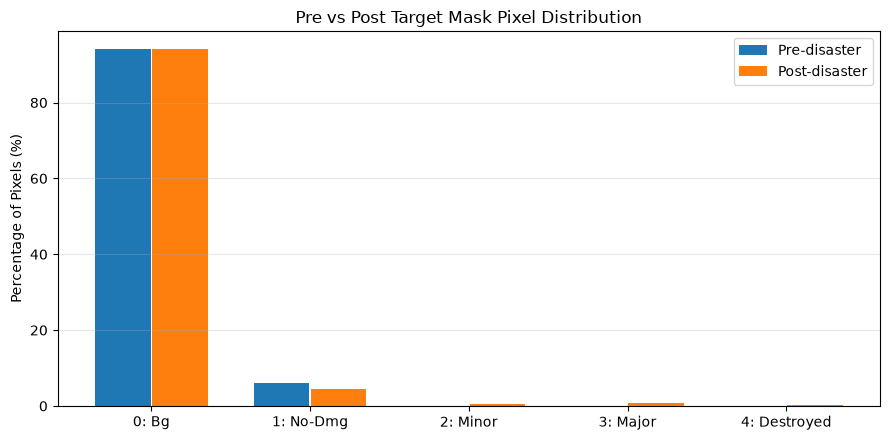

In [5]:
dim_counts, mode_counts = Counter(), Counter()
for img_path in (DATASET_ROOT / "train" / "images").glob("*.png"):
    with Image.open(img_path) as img:
        dim_counts[img.size] += 1
        mode_counts[img.mode] += 1
print("Image Dimensions:", dict(dim_counts), "| Color Modes:", dict(mode_counts))

targets_dir = DATASET_ROOT / "train" / "targets"
mask_pixel_counts = {"pre": Counter(), "post": Counter()}
mask_totals = {"pre": 0, "post": 0}
coverage = {"pre": [], "post": []}

for mask_path in sorted(targets_dir.glob("*.png")):
    kind = "pre" if "_pre_disaster_target" in mask_path.name else ("post" if "_post_disaster_target" in mask_path.name else None)
    if kind is None:
        continue
    arr = np.array(Image.open(mask_path))
    vals, cnts = np.unique(arr, return_counts=True)
    mask_pixel_counts[kind].update(dict(zip(vals.tolist(), cnts.tolist())))
    mask_totals[kind] += arr.size
    coverage[kind].append(np.count_nonzero(arr > 0) / arr.size * 100)

pixel_values = [0, 1, 2, 3, 4]
pre_pct = [mask_pixel_counts["pre"].get(v, 0) / mask_totals["pre"] * 100 for v in pixel_values]
post_pct = [mask_pixel_counts["post"].get(v, 0) / mask_totals["post"] * 100 for v in pixel_values]

print(f"Mean Foreground Coverage -> Pre: {np.mean(coverage['pre']):.2f}% | Post: {np.mean(coverage['post']):.2f}%")
x = np.arange(len(pixel_values))
plt.figure(figsize=(9, 4.5))
plt.bar(x - 0.18, pre_pct, 0.35, label="Pre-disaster")
plt.bar(x + 0.18, post_pct, 0.35, label="Post-disaster")
plt.xticks(x, ["0: Bg", "1: No-Dmg", "2: Minor", "3: Major", "4: Destroyed"])
plt.ylabel("Percentage of Pixels (%)")
plt.title("Pre vs Post Target Mask Pixel Distribution")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Representative Multi-Damage Sample & Polygon Alignment Check
Finds a tile containing at least three damage categories, visualizes its pre/post images and target masks, and verifies WKT polygon-to-mask pixel agreement.

Representative Multi-Damage Tile: guatemala-volcano_00000019
no-damage      -> Expected Mask 1 | Agreement: 100.00%
minor-damage   -> Expected Mask 2 | Agreement: 100.00%
major-damage   -> Expected Mask 3 | Agreement: 100.00%
destroyed      -> Expected Mask 4 | Agreement: 100.00%


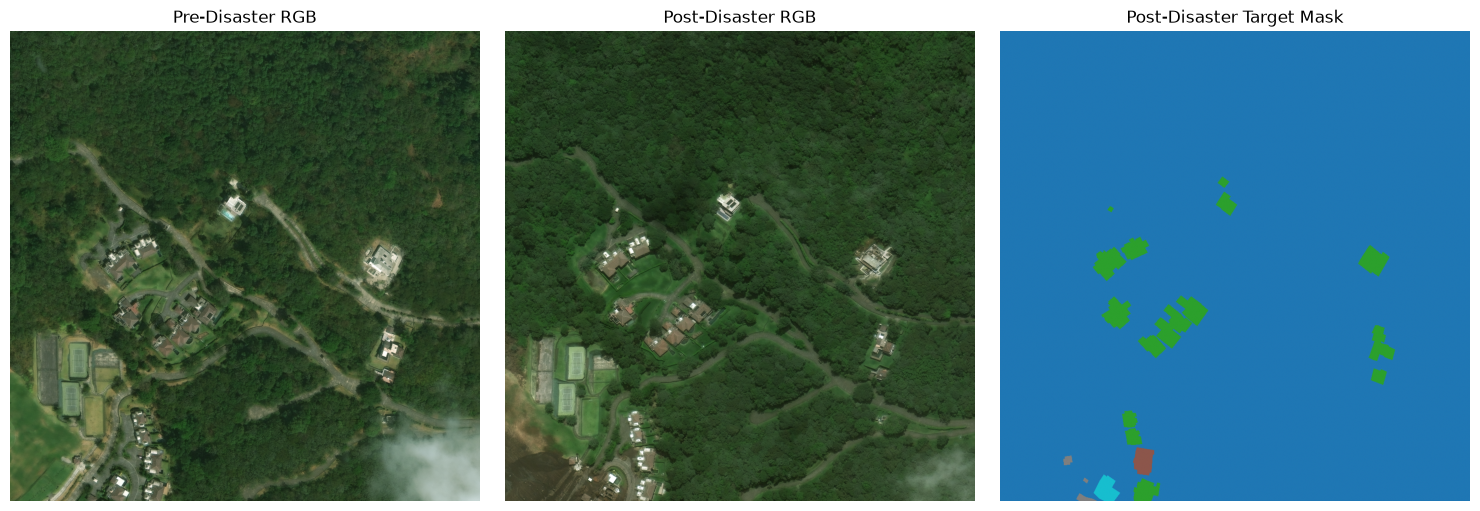

In [6]:
EXPECTED_MAPPING = {"no-damage": 1, "minor-damage": 2, "major-damage": 3, "destroyed": 4}
rep_tile_id = None

for json_path in sorted(train_labels_dir.glob("*_post_disaster.json")):
    with open(json_path, "r") as f:
        data = json.load(f)
    counts = Counter(b["properties"].get("subtype") for b in data["features"]["xy"])
    present = [k for k in EXPECTED_MAPPING if counts[k] > 0]
    if len(present) >= 3:
        rep_tile_id = json_path.stem.replace("_post_disaster", "")
        break

with open(train_labels_dir / f"{rep_tile_id}_post_disaster.json", "r") as f:
    rep_json = json.load(f)
rep_post_mask = np.array(Image.open(targets_dir / f"{rep_tile_id}_post_disaster_target.png"))

agreement = defaultdict(Counter)
for building in rep_json["features"]["xy"]:
    subtype = building["properties"].get("subtype")
    if subtype not in EXPECTED_MAPPING:
        continue
    poly = wkt.loads(building["wkt"])
    poly_img = Image.new("L", (rep_post_mask.shape[1], rep_post_mask.shape[0]), 0)
    ImageDraw.Draw(poly_img).polygon([(round(x), round(y)) for x, y in poly.exterior.coords], fill=1)
    vals, cnts = np.unique(rep_post_mask[np.array(poly_img, dtype=bool)], return_counts=True)
    for v, c in zip(vals, cnts):
        agreement[subtype][int(v)] += int(c)

print(f"Representative Multi-Damage Tile: {rep_tile_id}")
for subtype, exp_val in EXPECTED_MAPPING.items():
    obs = agreement[subtype]
    tot = sum(obs.values())
    pct = obs.get(exp_val, 0) / tot * 100 if tot else 0
    print(f"{subtype:<14} -> Expected Mask {exp_val} | Agreement: {pct:.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(Image.open(DATASET_ROOT / "train" / "images" / f"{rep_tile_id}_pre_disaster.png"))
axes[0].set_title("Pre-Disaster RGB")
axes[1].imshow(Image.open(DATASET_ROOT / "train" / "images" / f"{rep_tile_id}_post_disaster.png"))
axes[1].set_title("Post-Disaster RGB")
axes[2].imshow(rep_post_mask, cmap="tab10", vmin=0, vmax=4)
axes[2].set_title("Post-Disaster Target Mask")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Split Isolation, Disaster Distribution & Tier3 Assessment
Confirms zero tile leakage across `train`, `hold`, and `test`, maps disaster-event overlap, and summarizes `tier3` compatibility.

Verified zero tile ID overlap across train/hold/test splits.
                     train  hold  test
guatemala-volcano     True  True  True
hurricane-florence    True  True  True
hurricane-harvey      True  True  True
hurricane-matthew     True  True  True
hurricane-michael     True  True  True
mexico-earthquake     True  True  True
midwest-flooding      True  True  True
palu-tsunami          True  True  True
santa-rosa-wildfire   True  True  True
socal-fire            True  True  True
Tier3 Pairs: 6,369 | Pre-generated Targets: False (Excluded from supervised splits)


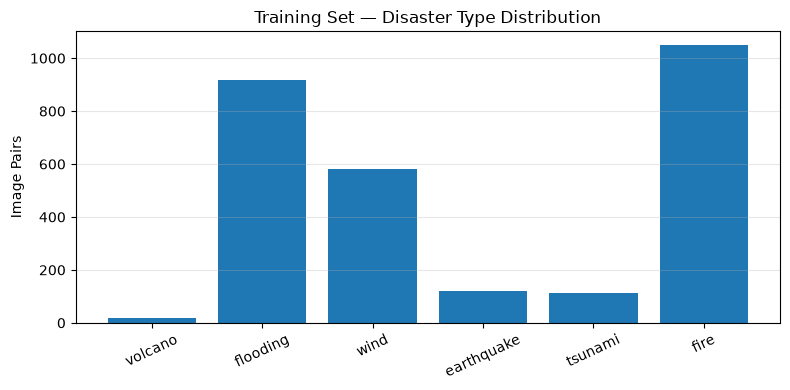

In [7]:
split_tile_ids = {}
split_disasters = {}
for split in ["train", "hold", "test"]:
    tile_ids = {p.stem.replace("_post_disaster", "") for p in (DATASET_ROOT / split / "images").glob("*_post_disaster.png")}
    split_tile_ids[split] = tile_ids
    disasters = set()
    for jp in (DATASET_ROOT / split / "labels").glob("*_post_disaster.json"):
        with open(jp) as f:
            disasters.add(json.load(f)["metadata"].get("disaster", "unknown"))
    split_disasters[split] = disasters

assert not (split_tile_ids["train"] & split_tile_ids["hold"])
assert not (split_tile_ids["train"] & split_tile_ids["test"])
assert not (split_tile_ids["hold"] & split_tile_ids["test"])
print("Verified zero tile ID overlap across train/hold/test splits.")

all_events = sorted(set.union(*split_disasters.values()))
event_matrix = pd.DataFrame({s: [e in split_disasters[s] for e in all_events] for s in ["train", "hold", "test"]}, index=all_events)
display(event_matrix)

tier3_imgs = len(list((DATASET_ROOT / "tier3" / "images").glob("*_post_disaster.png")))
tier3_targets = (DATASET_ROOT / "tier3" / "targets").exists()
print(f"Tier3 Pairs: {tier3_imgs:,} | Pre-generated Targets: {tier3_targets} (Excluded from supervised splits)")

plt.figure(figsize=(8, 4))
plt.bar(list(disaster_type_counts.keys()), list(disaster_type_counts.values()))
plt.title("Training Set — Disaster Type Distribution")
plt.ylabel("Image Pairs")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Dataset Audit — Conclusions

1. **Split Completeness**: `train` (2,799 pairs), `hold` (933 pairs), and `test` (933 pairs) contain 100% matched RGB images, GeoJSON annotations, and PNG masks with zero tile leakage across splits.
2. **Extreme Class Imbalance**: ~94% of pixels are background (`0`). Among annotated buildings, `no-damage` accounts for ~72.1%, while `minor-damage`, `major-damage`, and `destroyed` each represent ~8%–9%.
3. **Mask Semantics**: Pre-disaster masks are binary (`0=bg`, `1=building`), whereas post-disaster masks encode damage (`0=bg/unclassified`, `1..4=damage`). Unclassified buildings (`1.84%`) currently share pixel `0` with background and must be isolated using `ignore_index=255` in preprocessing.
4. **Tier3 Exclusion**: `tier3` (6,369 pairs) lacks pre-generated target masks and is excluded to maintain a clean, verified benchmark across the 4,665 primary tiles.